# Limpieza de dataset - Malaria (P. Vivax)

Issue: [#7](https://github.com/Jacogz/DL-QPI/issues/7)

Objetivo: construir el dominio de campo claro del dataset armonizado para el CycleGAN (objetivo específico 1), reduciendo la brecha con las imágenes de fase DHM.

Este notebook es parte de una serie que se corre secuencialmente en el mismo runtime: requiere que `01-eda-eritrocitos.ipynb` y `02-eda-malaria.ipynb` hayan dejado los datasets en disco.

## Pipeline
1. Validar que ambos datasets estén cargados.
2. Medir el tamaño de los eritrocitos en las imágenes de fase (tamaño objetivo).
3. RGB → escala de grises + normalización de intensidad por el fondo.
4. Rescale con un factor fijo por cámara para igualar el tamaño de célula al de fase (opción A).
5. Recorte en parches de 256x256 con solape (`STRIDE = 128`).
6. Eliminación **por parche**: toca una célula infectada / toca un leucocito o una caja `difficult` / menos de 3 células / cúmulos.
7. Split 80/20 por imagen de origen (igual que `Training`/`Validation` en fase).
8. Guardar parches + manifiesto. La aumentación (flips y rotaciones aleatorias) se aplica en el DataLoader, no en disco.
9. Comprimir la salida y copiarla a Drive.

## 0. Configuración

In [ ]:
import json
import random
import shutil
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage import filters, measure, morphology, segmentation
from tqdm.auto import tqdm

SEED = 123
random.seed(SEED)

PHASE_DIR = Path('/content/data/rbc_holograms/Phase')
PHASE_SPLITS = ('Training', 'Validation')

# Rutas donde puede quedar el dataset según cómo lo haya descargado 02-eda-malaria.ipynb
MALARIA_CANDIDATES = [
    Path('/content/data/pvivax_malaria/malaria'),
    Path('/kaggle/input/p-vivax-malaria-infected-human-blood-smears/malaria'),
    *sorted(Path('/content/data/datasets/orvile/p-vivax-malaria-infected-human-blood-smears').glob('versions/*/malaria')),
]

OUT_DIR = Path('/content/data/processed/malaria_processed')
DRIVE_OUT_DIR = Path('/content/drive/MyDrive/dl-qpi/data/processed')
ZIP_BASENAME = 'malaria_processed'

PATCH_SIZE = 256
STRIDE = 128
BG_TARGET = 200            # valor de gris al que se lleva el fondo de cada imagen
MIN_CELLS = 3
IOMIN_THRESH = 0.25        # intersección / área de la caja menor para considerar dos células solapadas
CLUSTER_FRAC_THRESH = 0.5  # fracción de células solapadas en el parche para descartarlo como cúmulo
VAL_FRAC = 0.2

HEALTHY = 'red blood cell'
INFECTED_CATS = {'trophozoite', 'ring', 'schizont', 'gametocyte'}
NON_ERYTHROCYTE = {'leukocyte', 'difficult'}

In [14]:
missing = [PHASE_DIR / s for s in PHASE_SPLITS if not (PHASE_DIR / s).is_dir()]
if missing:
    raise FileNotFoundError(
        f'No existe: {[str(m) for m in missing]}. '
        'Corre primero 01-eda-eritrocitos.ipynb para descomprimir el dataset de fase.'
    )
for s in PHASE_SPLITS:
    n = sum(1 for f in (PHASE_DIR / s).iterdir() if f.suffix.lower() == '.png')
    print(f'{PHASE_DIR / s}: {n} imágenes')

MALARIA_DIR = next((d for d in MALARIA_CANDIDATES if d.is_dir()), None)
if MALARIA_DIR is None:
    raise FileNotFoundError(
        f'No se encontró el dataset de malaria en {[str(d) for d in MALARIA_CANDIDATES]}. '
        'Corre primero 02-eda-malaria.ipynb.'
    )
print(f'{MALARIA_DIR}: {len(list(MALARIA_DIR.glob("*.json")))} JSON de anotaciones')

/content/data/rbc_holograms/Phase/Training: 29491 imágenes
/content/data/rbc_holograms/Phase/Validation: 7373 imágenes
/content/data/pvivax_malaria/malaria: 2 JSON de anotaciones


## 1. Tamaño de referencia de las células en el dominio de fase

El rescale debe llevar las células de malaria al tamaño que tienen en las imágenes de fase DHM (reunión 2026-10-28). Aquí se mide ese tamaño segmentando eritrocitos sobre una muestra del split `Training` del dataset de fase.

Se reporta la misma métrica que se usa en malaria con las bounding boxes, `(alto + ancho) / 2` de la caja, para que ambos dominios sean comparables, y además el diámetro equivalente `sqrt(4·área/π)`.

Referencia teórica: con el objetivo 40× y el píxel de 5.86 µm del paper, el píxel efectivo es ~0.15 µm, así que un eritrocito de 7–8 µm debería medir ~48–55 px.

### Segmentación de eritrocitos en fase

Umbral de Otsu sobre la imagen suavizada (se asume que las células tienen más fase que el fondo, es decir, se ven más claras), apertura morfológica y relleno de huecos (el centro bicóncavo tiene menos fase y puede quedar como hueco). Se descartan:
- componentes que tocan el borde: son células cortadas por el recorte a 256x256 y subestimarían el tamaño;
- componentes de menos de `MIN_AREA` px: ruido;
- componentes con solidez menor a `MIN_SOLIDITY`: suelen ser células pegadas que se segmentan como una sola.

Antes de medir, revisar en la figura que las cajas caen sobre las células.

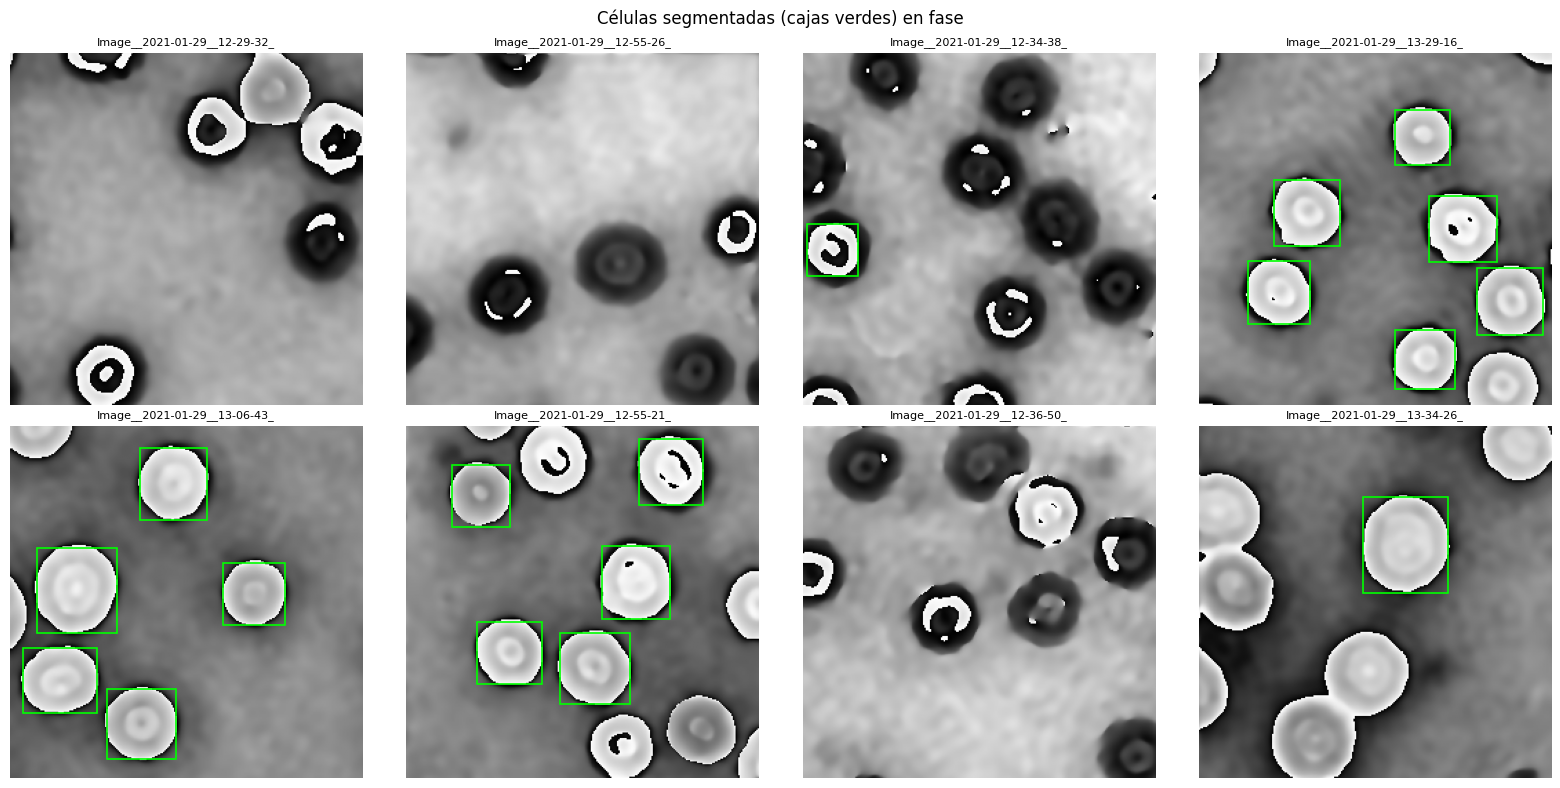

In [15]:
N_PHASE_SAMPLE = 500
MIN_AREA = 200
MIN_SOLIDITY = 0.9


def segment_phase_cells(arr):
    smooth = filters.gaussian(arr, sigma=2, preserve_range=True)
    mask = smooth > filters.threshold_otsu(smooth)
    mask = ndi.binary_opening(mask, structure=morphology.disk(3))
    mask = ndi.binary_fill_holes(mask)
    mask = segmentation.clear_border(mask)
    regions = measure.regionprops(measure.label(mask))
    return [r for r in regions if r.area >= MIN_AREA and r.solidity >= MIN_SOLIDITY]


phase_train_files = sorted(f for f in (PHASE_DIR / 'Training').iterdir() if f.suffix.lower() == '.png')
phase_sample = random.sample(phase_train_files, min(N_PHASE_SAMPLE, len(phase_train_files)))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, fp in zip(axes.ravel(), phase_sample[:8]):
    arr = np.array(Image.open(fp).convert('L'), dtype=np.float32)
    ax.imshow(arr, cmap='gray')
    for r in segment_phase_cells(arr):
        r0, c0, r1, c1 = r.bbox
        ax.add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='lime', lw=1.2))
    ax.set_title(fp.name[:28], fontsize=8)
    ax.axis('off')
plt.suptitle('Células segmentadas (cajas verdes) en fase')
plt.tight_layout()
plt.show()

Células medidas: 910 en 314/500 imágenes de la muestra
Células por imagen (mediana): 3

       bbox_size  eq_diameter
count      910.0        910.0
mean        50.6         50.0
std          7.5          7.4
min         17.0         16.0
25%         47.5         46.9
50%         51.0         50.6
75%         54.5         53.8
max        141.0        132.7

PHASE_CELL_SIZE_PX (mediana de (alto+ancho)/2 de la caja) = 51.0 px


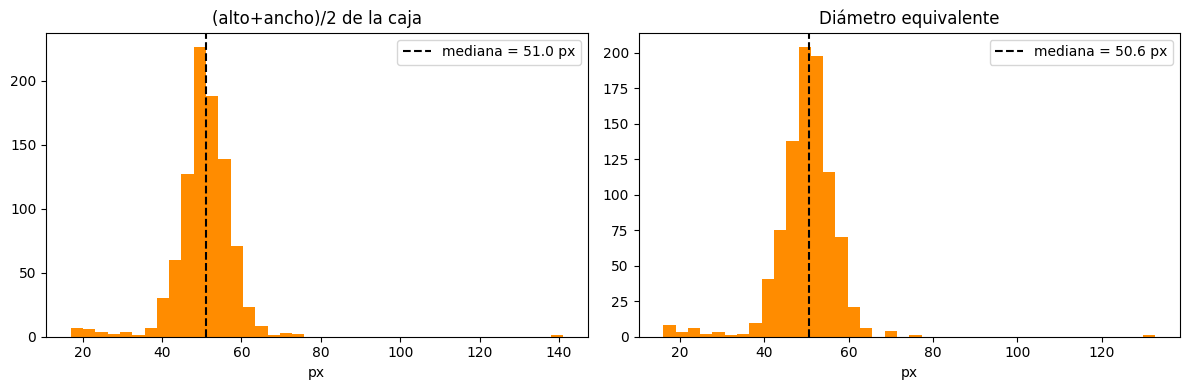

In [16]:
phase_cell_rows = []
for fp in phase_sample:
    arr = np.array(Image.open(fp).convert('L'), dtype=np.float32)
    for r in segment_phase_cells(arr):
        r0, c0, r1, c1 = r.bbox
        phase_cell_rows.append({
            'image': fp.name,
            'bbox_size': ((r1 - r0) + (c1 - c0)) / 2,
            'eq_diameter': np.sqrt(4 * r.area / np.pi),
        })

phase_cells_df = pd.DataFrame(phase_cell_rows)
n_imgs_with_cells = phase_cells_df['image'].nunique()
print(f'Células medidas: {len(phase_cells_df)} en {n_imgs_with_cells}/{len(phase_sample)} imágenes de la muestra')
print(f'Células por imagen (mediana): {phase_cells_df.groupby("image").size().median():.0f}')
print()
print(phase_cells_df[['bbox_size', 'eq_diameter']].describe(percentiles=[0.25, 0.5, 0.75]).round(1))

# Tamaño objetivo para el rescale de malaria: misma métrica que las cajas de malaria
PHASE_CELL_SIZE_PX = float(phase_cells_df['bbox_size'].median())
print(f'\nPHASE_CELL_SIZE_PX (mediana de (alto+ancho)/2 de la caja) = {PHASE_CELL_SIZE_PX:.1f} px')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, label in zip(axes, ['bbox_size', 'eq_diameter'], ['(alto+ancho)/2 de la caja', 'Diámetro equivalente']):
    values = phase_cells_df[col]
    ax.hist(values, bins=40, color='darkorange')
    ax.axvline(values.median(), color='k', ls='--', label=f'mediana = {values.median():.1f} px')
    ax.set_title(label)
    ax.set_xlabel('px')
    ax.legend()
plt.tight_layout()
plt.show()

## 2. Anotaciones de malaria

Una fila por caja, con el tamaño de la imagen tomado del JSON. El tamaño identifica la cámara: 1600x1200 (PNG) y 1944x1383 (JPG), ver `02-eda-malaria.ipynb`.

In [17]:
malaria_images = {f.name: f for f in MALARIA_DIR.rglob('*') if f.suffix.lower() in {'.png', '.jpg', '.jpeg'}}

annotation_rows = []
for jf in sorted(MALARIA_DIR.glob('*.json')):
    with open(jf) as f:
        entries = json.load(f)
    for entry in entries:
        name = Path(entry['image']['pathname']).name
        shape = entry['image']['shape']
        for obj in entry['objects']:
            bb = obj['bounding_box']
            annotation_rows.append({
                'image_name': name,
                'split_kaggle': jf.stem,
                'camera': f"{shape['c']}x{shape['r']}",
                'category': obj['category'],
                'r0': bb['minimum']['r'], 'c0': bb['minimum']['c'],
                'r1': bb['maximum']['r'], 'c1': bb['maximum']['c'],
            })

ann_df = pd.DataFrame(annotation_rows)
ann_df['box_size'] = ((ann_df['r1'] - ann_df['r0']) + (ann_df['c1'] - ann_df['c0'])) / 2
boxes_by_image = dict(tuple(ann_df.groupby('image_name')))

images_df = ann_df.groupby('image_name').agg(
    split_kaggle=('split_kaggle', 'first'),
    camera=('camera', 'first'),
    n_infected=('category', lambda s: s.isin(INFECTED_CATS).sum()),
).reset_index()

missing_files = sorted(set(images_df['image_name']) - set(malaria_images))
print(f'Anotaciones: {len(ann_df)} | imágenes anotadas: {len(images_df)} | sin archivo en disco: {len(missing_files)}')
print(images_df.groupby(['camera', 'split_kaggle']).size().rename('imágenes'))

Anotaciones: 86035 | imágenes anotadas: 1328 | sin archivo en disco: 0
camera     split_kaggle
1600x1200  training        1208
1944x1383  test             120
Name: imágenes, dtype: int64


## 3. Factor de escala por cámara (opción A)

Un único factor por cámara: `PHASE_CELL_SIZE_PX / mediana del tamaño de caja de los eritrocitos sanos de esa cámara`. Se usan solo las cajas `red blood cell` porque *P. vivax* agranda la célula infectada.

Frente a un factor por imagen, esto conserva la variación real de tamaño entre células e imágenes, que es lo que mide la conservación morfológica del objetivo 3. La dispersión de la mediana por imagen dentro de cada cámara indica si basta con un factor fijo: un CV bajo (≲ 0.1) significa que el aumento es estable dentro de la cámara.

Limitación: las cajas de malaria son anotaciones manuales y suelen dejar un margen alrededor de la célula; las de fase salen de una segmentación ajustada. Si hay sesgo, las células de malaria quedan unos px más pequeñas de lo debido.

           imagenes  mediana_por_imagen    p25    p75     cv  \
camera                                                         
1600x1200      1208             110.250  103.5  117.0  0.077   
1944x1383       120             137.125  131.5  140.0  0.049   

           tamano_celula_px  factor_escala  
camera                                      
1600x1200             107.5          0.474  
1944x1383             136.5          0.374  
1600x1200: x0.474 -> 759x569 px
1944x1383: x0.374 -> 726x517 px


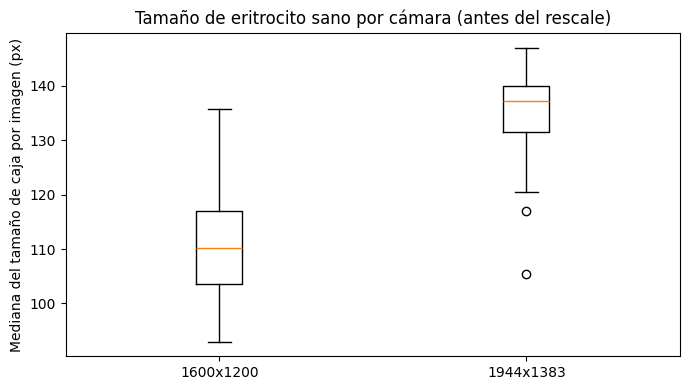

In [18]:
healthy_df = ann_df[ann_df['category'] == HEALTHY]
per_image_size = healthy_df.groupby(['camera', 'image_name'])['box_size'].median().reset_index()

camera_summary = per_image_size.groupby('camera')['box_size'].agg(
    imagenes='size',
    mediana_por_imagen='median',
    p25=lambda s: s.quantile(0.25),
    p75=lambda s: s.quantile(0.75),
    cv=lambda s: s.std() / s.mean(),
)
camera_cell_size = healthy_df.groupby('camera')['box_size'].median()
camera_summary['tamano_celula_px'] = camera_cell_size
camera_summary['factor_escala'] = PHASE_CELL_SIZE_PX / camera_cell_size
CAMERA_SCALE = camera_summary['factor_escala'].to_dict()
print(camera_summary.round(3))

for camera, scale in CAMERA_SCALE.items():
    w, h = map(int, camera.split('x'))
    print(f'{camera}: x{scale:.3f} -> {round(w * scale)}x{round(h * scale)} px')

fig, ax = plt.subplots(figsize=(7, 4))
cams = sorted(CAMERA_SCALE)
ax.boxplot([per_image_size.loc[per_image_size['camera'] == c, 'box_size'] for c in cams])
ax.set_xticks(range(1, len(cams) + 1), cams)
ax.set_ylabel('Mediana del tamaño de caja por imagen (px)')
ax.set_title('Tamaño de eritrocito sano por cámara (antes del rescale)')
plt.tight_layout()
plt.show()

## 4. Funciones del pipeline

- **Gris + normalización:** `L` de PIL (ITU-R 601). El fondo se estima como la mediana de los píxeles fuera de todas las cajas y se lleva a `BG_TARGET`, para quitar las diferencias de iluminación entre imágenes y cámaras.
- **Rescale:** Lanczos con el factor de la cámara; las cajas se escalan con el mismo factor.
- **Ventanas:** paso `STRIDE`, y se agrega una última ventana pegada al borde para no perder la franja final.
- **Criterios por parche**, en este orden (el parche se cuenta en el primero que cumple):
  1. `toca_infectada`: cualquier caja infectada se solapa con el parche, aunque sea en parte.
  2. `toca_leucocito_o_difficult`: lo mismo con leucocitos (no existen en fase) y cajas `difficult` (podrían ser infectadas).
  3. `menos_de_3_celulas`: eritrocitos sanos con el centro dentro del parche.
  4. `cumulos`: fracción de esas células que se solapan con otra (intersección / área de la menor ≥ `IOMIN_THRESH`) ≥ `CLUSTER_FRAC_THRESH`. Los umbrales son iniciales: revisar los ejemplos de la sección 7 y ajustar.

In [19]:
def to_normalized_gray(img_rgb, boxes):
    gray = np.asarray(img_rgb.convert('L'), dtype=np.float32)
    bg_mask = np.ones(gray.shape, dtype=bool)
    for r0, c0, r1, c1 in boxes:
        bg_mask[max(r0, 0):r1, max(c0, 0):c1] = False
    bg = float(np.median(gray[bg_mask])) if bg_mask.any() else float(np.percentile(gray, 90))
    return np.clip(gray * (BG_TARGET / bg), 0, 255).astype(np.uint8), bg


def window_starts(length):
    starts = list(range(0, length - PATCH_SIZE + 1, STRIDE))
    if starts and starts[-1] != length - PATCH_SIZE:
        starts.append(length - PATCH_SIZE)
    return starts


def iomin_matrix(boxes):
    r0 = np.maximum(boxes[:, None, 0], boxes[None, :, 0])
    c0 = np.maximum(boxes[:, None, 1], boxes[None, :, 1])
    r1 = np.minimum(boxes[:, None, 2], boxes[None, :, 2])
    c1 = np.minimum(boxes[:, None, 3], boxes[None, :, 3])
    inter = np.clip(r1 - r0, 0, None) * np.clip(c1 - c0, 0, None)
    area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])
    m = inter / np.maximum(np.minimum(area[:, None], area[None, :]), 1e-6)
    np.fill_diagonal(m, 0)
    return m


def classify_patch(r, c, boxes, cats):
    """Cajas en coordenadas reescaladas. Devuelve (motivo, cajas de las células en coordenadas del parche)."""
    r_end, c_end = r + PATCH_SIZE, c + PATCH_SIZE
    touches = (boxes[:, 0] < r_end) & (boxes[:, 2] > r) & (boxes[:, 1] < c_end) & (boxes[:, 3] > c)
    if (touches & np.isin(cats, list(INFECTED_CATS))).any():
        return 'toca_infectada', None
    if (touches & np.isin(cats, list(NON_ERYTHROCYTE))).any():
        return 'toca_leucocito_o_difficult', None
    center_r = (boxes[:, 0] + boxes[:, 2]) / 2
    center_c = (boxes[:, 1] + boxes[:, 3]) / 2
    inside = (cats == HEALTHY) & (center_r >= r) & (center_r < r_end) & (center_c >= c) & (center_c < c_end)
    cells = boxes[inside]
    if len(cells) < MIN_CELLS:
        return 'menos_de_3_celulas', None
    if (iomin_matrix(cells) >= IOMIN_THRESH).any(axis=1).mean() >= CLUSTER_FRAC_THRESH:
        return 'cumulos', None
    return 'mantenido', np.clip(cells - [r, c, r, c], 0, PATCH_SIZE)


def process_image(name):
    g = boxes_by_image[name]
    boxes = g[['r0', 'c0', 'r1', 'c1']].to_numpy()
    cats = g['category'].to_numpy()
    camera = g['camera'].iloc[0]
    scale = CAMERA_SCALE[camera]

    rgb = Image.open(malaria_images[name]).convert('RGB')
    gray, bg = to_normalized_gray(rgb, boxes)
    h, w = gray.shape
    resized = np.asarray(Image.fromarray(gray).resize((round(w * scale), round(h * scale)), Image.Resampling.LANCZOS))

    boxes_scaled = boxes * scale
    patches = [
        {'r': r, 'c': c, **dict(zip(('motivo', 'cells'), classify_patch(r, c, boxes_scaled, cats)))}
        for r in window_starts(resized.shape[0])
        for c in window_starts(resized.shape[1])
    ]
    return {'rgb': rgb, 'gray': gray, 'resized': resized, 'scale': scale, 'camera': camera, 'bg': bg, 'patches': patches}

## 5. Ejemplo antes/después

Una imagen con pocas células infectadas: con el filtro por parche se aprovechan las zonas sanas de la imagen en vez de descartarla entera.

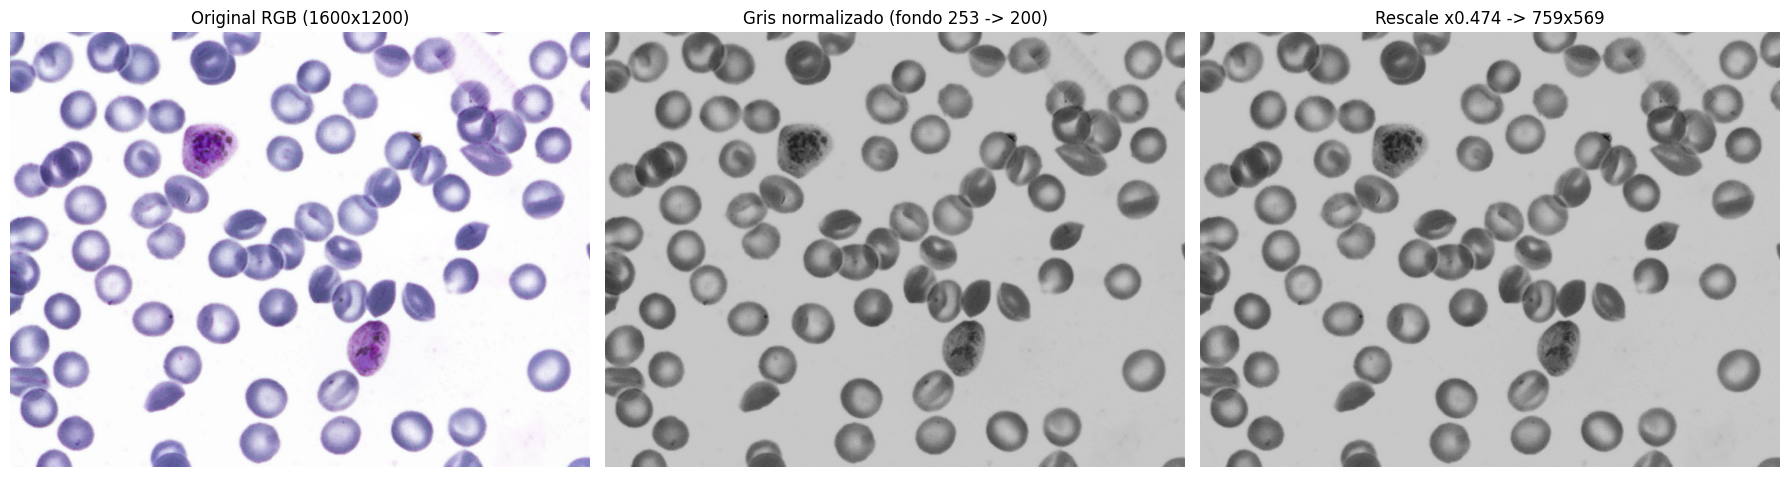

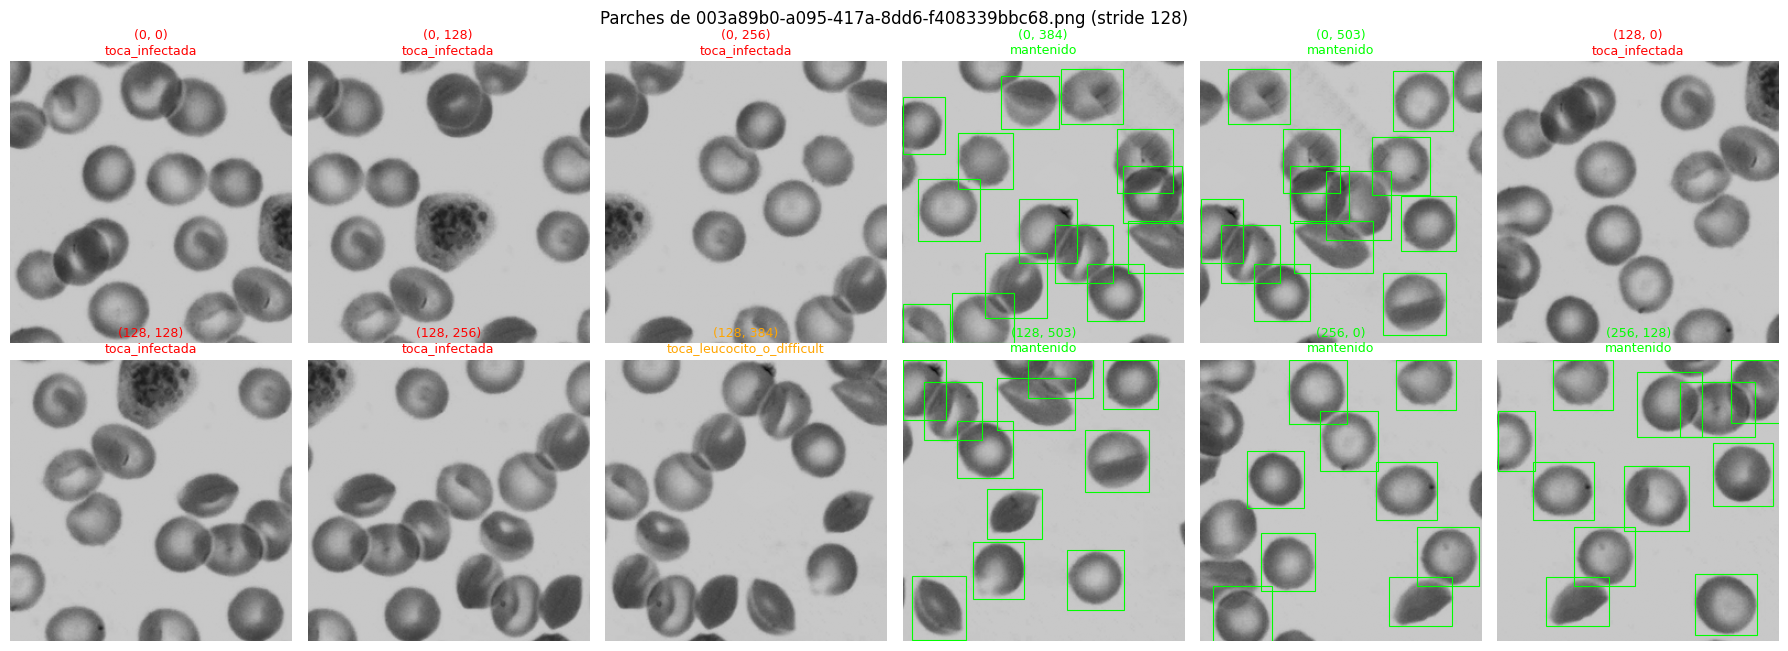

In [20]:
MOTIVO_COLORS = {
    'mantenido': 'lime',
    'toca_infectada': 'red',
    'toca_leucocito_o_difficult': 'orange',
    'menos_de_3_celulas': 'deepskyblue',
    'cumulos': 'magenta',
}

example_name = images_df[(images_df['n_infected'].between(1, 2)) & images_df['image_name'].isin(malaria_images)]['image_name'].iloc[0]
example = process_image(example_name)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(example['rgb'])
axes[0].set_title(f'Original RGB ({example["camera"]})')
axes[1].imshow(example['gray'], cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f'Gris normalizado (fondo {example["bg"]:.0f} -> {BG_TARGET})')
axes[2].imshow(example['resized'], cmap='gray', vmin=0, vmax=255)
axes[2].set_title(f'Rescale x{example["scale"]:.3f} -> {example["resized"].shape[1]}x{example["resized"].shape[0]}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

n_show = min(12, len(example['patches']))
fig, axes = plt.subplots(int(np.ceil(n_show / 6)), 6, figsize=(18, 3.3 * int(np.ceil(n_show / 6))), squeeze=False)
for ax in axes.ravel():
    ax.axis('off')
for ax, p in zip(axes.ravel(), example['patches'][:n_show]):
    ax.imshow(example['resized'][p['r']:p['r'] + PATCH_SIZE, p['c']:p['c'] + PATCH_SIZE], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'({p["r"]}, {p["c"]})\n{p["motivo"]}', fontsize=9, color=MOTIVO_COLORS[p['motivo']])
    if p['cells'] is not None:
        for r0, c0, r1, c1 in p['cells']:
            ax.add_patch(plt.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='lime', lw=0.8))
plt.suptitle(f'Parches de {example_name} (stride {STRIDE})')
plt.tight_layout()
plt.show()

## 6. Split 80/20 por imagen de origen

Los parches de una misma imagen (y más con solape) están correlacionados, así que el split se hace por imagen y se estratifica por cámara. Se usan los nombres `Training`/`Validation` del dataset de fase. El split original de Kaggle (`training`/`test`) se conserva en el manifiesto, pero no se usa porque su `test` es justamente la otra cámara.

In [21]:
split_by_image = {}
for camera, g in images_df[images_df['image_name'].isin(malaria_images)].groupby('camera'):
    names = sorted(g['image_name'])
    random.Random(SEED).shuffle(names)
    n_val = round(len(names) * VAL_FRAC)
    for i, name in enumerate(names):
        split_by_image[name] = 'Validation' if i < n_val else 'Training'

images_df['split'] = images_df['image_name'].map(split_by_image)
print(images_df.groupby(['camera', 'split']).size().unstack(fill_value=0))

split      Training  Validation
camera                         
1600x1200       966         242
1944x1383        96          24


## 7. Procesar y guardar

Se guardan los parches mantenidos como PNG en `OUT_DIR/<split>/`, junto con:
- `manifest.csv`: un parche por fila, con la imagen de origen, la cámara, el factor de escala, el fondo estimado, la posición del parche en la imagen reescalada, el nº de células y sus cajas en coordenadas del parche (JSON). Las cajas sirven para la segmentación y el perfil de fase de #8 y para medir la conservación morfológica.
- `params.json`: los parámetros con los que se generó la salida.

Antes de escribir, se borra lo que generó una corrida anterior de este notebook.

In [22]:
for split in PHASE_SPLITS:
    shutil.rmtree(OUT_DIR / split, ignore_errors=True)
    (OUT_DIR / split).mkdir(parents=True)

manifest_rows = []
motivo_counts = Counter()
removed_examples = defaultdict(list)

for name in tqdm(sorted(split_by_image)):
    res = process_image(name)
    split = split_by_image[name]
    for p in res['patches']:
        motivo_counts[p['motivo']] += 1
        patch = res['resized'][p['r']:p['r'] + PATCH_SIZE, p['c']:p['c'] + PATCH_SIZE]
        if p['motivo'] != 'mantenido':
            if len(removed_examples[p['motivo']]) < 6 and random.random() < 0.1:
                removed_examples[p['motivo']].append(patch)
            continue
        fname = f"{Path(name).stem}_r{p['r']:04d}_c{p['c']:04d}.png"
        Image.fromarray(patch).save(OUT_DIR / split / fname)
        manifest_rows.append({
            'file': f'{split}/{fname}',
            'split': split,
            'source_image': name,
            'split_kaggle': boxes_by_image[name]['split_kaggle'].iloc[0],
            'camera': res['camera'],
            'scale': round(res['scale'], 4),
            'bg_value': round(res['bg'], 1),
            'patch_r': p['r'],
            'patch_c': p['c'],
            'n_cells': len(p['cells']),
            'cell_boxes': json.dumps(np.round(p['cells']).astype(int).tolist()),
        })

manifest_df = pd.DataFrame(manifest_rows)
manifest_df.to_csv(OUT_DIR / 'manifest.csv', index=False)

params = {
    'seed': SEED,
    'phase_cell_size_px': PHASE_CELL_SIZE_PX,
    'camera_cell_size_px': camera_cell_size.to_dict(),
    'camera_scale': CAMERA_SCALE,
    'patch_size': PATCH_SIZE,
    'stride': STRIDE,
    'bg_target': BG_TARGET,
    'min_cells': MIN_CELLS,
    'iomin_thresh': IOMIN_THRESH,
    'cluster_frac_thresh': CLUSTER_FRAC_THRESH,
    'val_frac': VAL_FRAC,
    'patch_counts': dict(motivo_counts),
}
with open(OUT_DIR / 'params.json', 'w') as f:
    json.dump(params, f, indent=2)

total = sum(motivo_counts.values())
print(f'Imágenes procesadas: {len(split_by_image)} (sin archivo en disco: {len(missing_files)})')
print(f'Parches evaluados: {total}\n')
print('Parches por criterio:')
for motivo in MOTIVO_COLORS:
    print(f'  {motivo}: {motivo_counts[motivo]} ({100 * motivo_counts[motivo] / total:.1f}%)')
print()
print(manifest_df.groupby('split').agg(parches=('file', 'size'), imagenes_origen=('source_image', 'nunique'), celulas_mediana=('n_cells', 'median')))
print(f'\nSalida: {OUT_DIR}')

  0%|          | 0/1328 [00:00<?, ?it/s]

Imágenes procesadas: 1328 (sin archivo en disco: 0)
Parches evaluados: 26560

Parches por criterio:
  mantenido: 12616 (47.5%)
  toca_infectada: 9198 (34.6%)
  toca_leucocito_o_difficult: 1867 (7.0%)
  menos_de_3_celulas: 849 (3.2%)
  cumulos: 2030 (7.6%)

            parches  imagenes_origen  celulas_mediana
split                                                
Training      10099             1004              9.0
Validation     2517              255              8.0

Salida: /content/data/rbc_holograms/processed


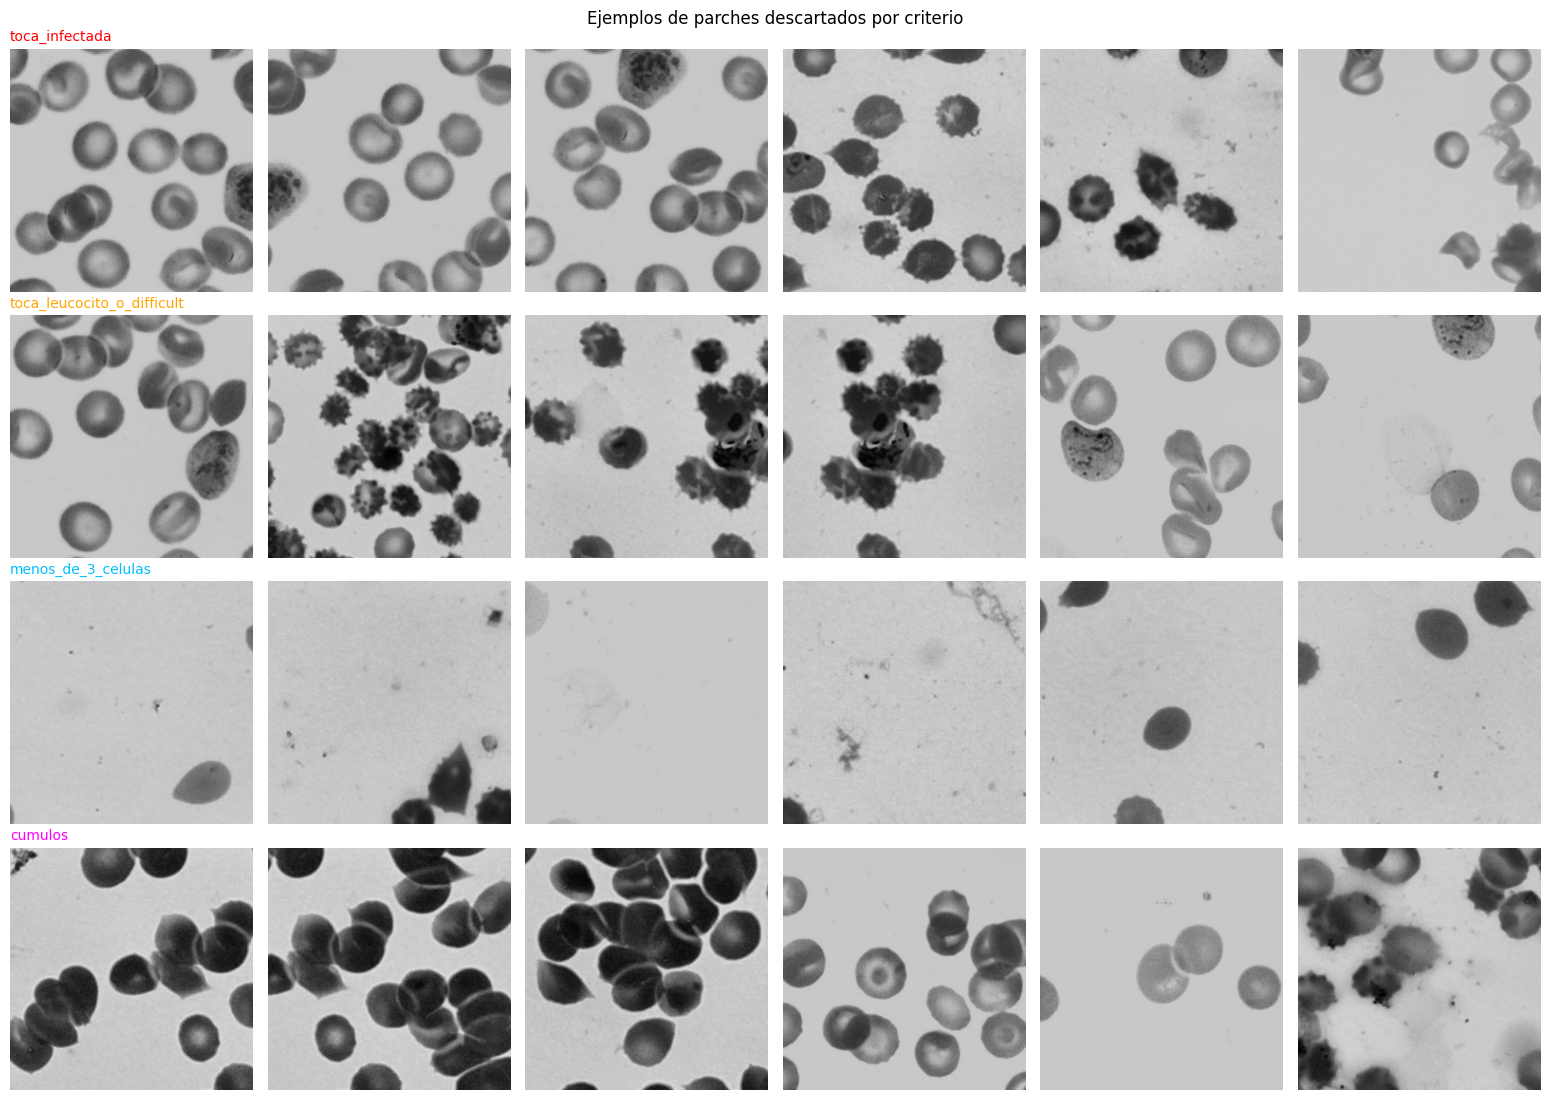

In [23]:
removed_motivos = [m for m in MOTIVO_COLORS if m != 'mantenido' and removed_examples[m]]
if removed_motivos:
    n_cols = max(len(removed_examples[m]) for m in removed_motivos)
    fig, axes = plt.subplots(len(removed_motivos), n_cols, figsize=(2.6 * n_cols, 2.8 * len(removed_motivos)), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for row, motivo in zip(axes, removed_motivos):
        row[0].set_title(motivo, loc='left', fontsize=10, color=MOTIVO_COLORS[motivo])
        for ax, patch in zip(row, removed_examples[motivo]):
            ax.imshow(patch, cmap='gray', vmin=0, vmax=255)
    plt.suptitle('Ejemplos de parches descartados por criterio')
    plt.tight_layout()
    plt.show()

## 8. Aumentación de datos (flips y rotaciones aleatorias)

No se guarda en disco: copias fijas de cada parche inflarían el dataset y, si se generan antes del split, se filtrarían entre `Training` y `Validation`. Se aplica al azar en el `Dataset` de PyTorch al cargar cada parche, tanto para malaria como para fase.

Se usan las 8 simetrías del cuadrado (rotaciones de 90° × flip): no interpolan ni dejan esquinas vacías, y los eritrocitos no tienen orientación preferida.

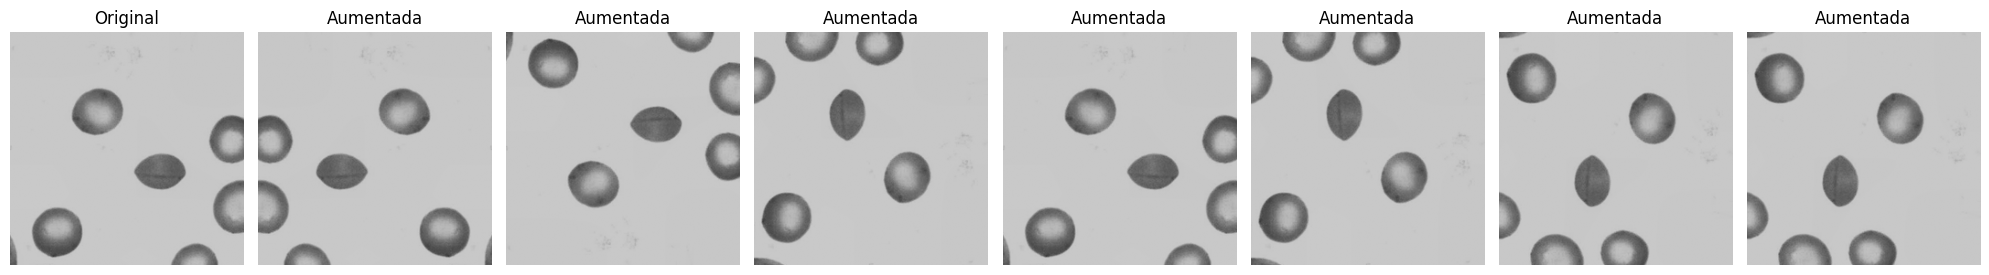

In [24]:
def random_dihedral(patch, rng):
    """Aplica al azar una de las 8 simetrías del cuadrado. Pensada para usarse dentro del Dataset."""
    patch = np.rot90(patch, k=int(rng.integers(4)))
    return np.fliplr(patch) if rng.random() < 0.5 else patch


aug_rng = np.random.default_rng(SEED)
demo_patch = np.array(Image.open(OUT_DIR / manifest_df['file'].iloc[0]))

fig, axes = plt.subplots(1, 8, figsize=(20, 3))
axes[0].imshow(demo_patch, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Original')
for ax in axes[1:]:
    ax.imshow(random_dihedral(demo_patch, aug_rng), cmap='gray', vmin=0, vmax=255)
    ax.set_title('Aumentada')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

## 9. Comprimir y copiar a Drive

In [25]:
if not Path('/content/drive/MyDrive').is_dir():
    from google.colab import drive
    drive.mount('/content/drive')

zip_path = Path(shutil.make_archive(str(OUT_DIR.parent / ZIP_BASENAME), 'zip', root_dir=OUT_DIR))
DRIVE_OUT_DIR.mkdir(parents=True, exist_ok=True)
drive_zip = Path(shutil.copy2(zip_path, DRIVE_OUT_DIR / zip_path.name))
print(f'{zip_path} ({zip_path.stat().st_size / 1024 ** 2:.1f} MB) -> {drive_zip}')

/content/data/rbc_holograms/malaria_processed.zip (350.7 MB) -> /content/drive/MyDrive/dl-qpi/data/processed/malaria_processed.zip
